# Decision gate check: where do the marks go after the pipeline ran?
Input: per-photo tables of Member 1's sweep (9-heading pipeline, edge ZNCC, K50, M10, LoFTR-MINIMA). Question: how much is lost by the answer/skip rule (bar 8 inliers) and can a gate on inliers + coarse z get it back, tested honestly (groups never seen in training)?

In [1]:
import sys, pathlib, glob, warnings
warnings.filterwarnings("ignore")
here = pathlib.Path.cwd()
repo = next(p for p in [here, *here.parents] if (p / "src").is_dir() and (p / "train" / "checks").is_dir())
sys.path[:0] = [str(repo), str(repo / "src")]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from train.checks.decision_gate import *
INPUT = repo / "tests/Test_Iteration_3/results/input"
CONFIDENCE = "0.22"      # settings: 0.20 or 0.22

In [2]:
official = pd.read_csv(INPUT / f"official500_conf{CONFIDENCE}.csv")
nudt = pd.concat([pd.read_csv(f) for f in sorted(INPUT.glob(f"nudt_conf{CONFIDENCE}_part*.csv"))])
points = points_from_error(official.error_sigma.values)
n = len(official)
print("official", n, "current score %.2f" % (official.points.sum()/n*6))
print("ceiling (answer exactly the photos that earn): %.2f" % score_of_flags(points, points > 0)[0])
print("always answer: %.2f" % score_of_flags(points, np.ones(n, bool))[0])
print(loss_breakdown(official), "(of", n*10, "possible points)")

official 500 current score 49.00
ceiling (answer exactly the photos that earn): 55.12
always answer: 48.40
{'skipped_but_good': 510, 'imprecise': 87, 'wrong_answers': 0, 'skipped_and_far_off': 28} (of 5000 possible points)


## Result 1: the gate loses ~6 of the 60 marks
Skipped photos that were in fact right are the biggest leak; wrong answers cost nothing at bar 8 on this set (but the sweep shows what a lower bar risks).

In [3]:
groups = {"height decile": pd.qcut(official.height, 10, labels=False, duplicates="drop").values,
          "photo-id block": official.photo.values // 50}
models = {"logit": lambda: LogisticRegression(C=1, max_iter=2000),
          "gbm":   lambda: GradientBoostingClassifier(n_estimators=60, max_depth=2, random_state=0)}
rows = [["current rule (bar 8)", official.points.sum()/n*6, int((official.points == -20).sum())]]
for gname, g in groups.items():
    for mname, make in models.items():
        flags = grouped_cv_gate(official, make, g, 0.6)
        s, w = score_of_flags(points, flags)
        rows.append([f"{mname}, grouped by {gname}", s, w])
rows.append(["ceiling", score_of_flags(points, points > 0)[0], 0])
table = pd.DataFrame(rows, columns=["gate", "score/60", "wrong"]).round(2)
table

,gate,score/60,wrong
0,current rule (bar 8),49.00,0
1,"logit, grouped by height decile",54.40,3
2,"gbm, grouped by height decile",54.40,3
3,"logit, grouped by photo-id block",54.88,1
4,"gbm, grouped by photo-id block",54.64,1
5,ceiling,55.12,0


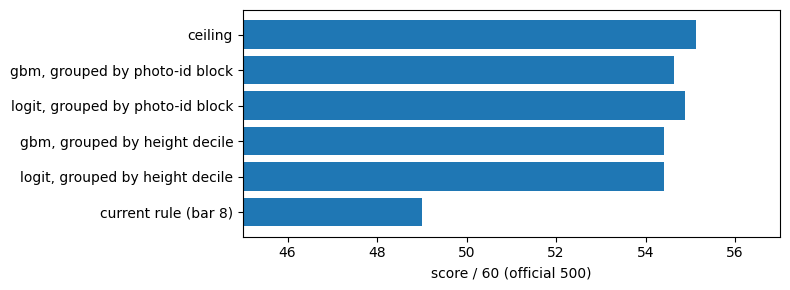

In [4]:
plt.figure(figsize=(8, 3)); plt.barh(table.gate, table["score/60"]); plt.xlim(45, 57)
plt.xlabel("score / 60 (official 500)"); plt.tight_layout(); plt.show()

## Result 2 (negative): a gate learned on one dataset does not carry to another
Trained on NUDT and tested on official it still gains (about +3.5, no wrong answers); trained on official and tested on NUDT it admits 50-74 wrong answers and loses 2-4 marks. The final map (Cartosat) is a third distribution, so the gate needs an in-domain held-out set, and wrong answers (-20) must be watched as the first number.

In [5]:
pn = points_from_error(nudt.error_sigma.values); out = []
for mname, make in models.items():
    m = make().fit(gate_features(nudt), (pn > 0).astype(int))
    f = m.predict_proba(gate_features(official))[:, 1] > 0.6
    out.append([mname + " NUDT->official", *score_of_flags(points, f), "current %.2f" % (official.points.sum()/n*6)])
    m = make().fit(gate_features(official), (points > 0).astype(int))
    f = m.predict_proba(gate_features(nudt))[:, 1] > 0.6
    out.append([mname + " official->NUDT", *score_of_flags(pn, f), "current %.2f" % (nudt.points.sum()/len(nudt)*6)])
pd.DataFrame(out, columns=["transfer", "score/60", "wrong", "baseline"]).round(2)

,transfer,score/60,wrong,baseline
0,logit NUDT->official,52.52,0,current 49.00
1,logit official->NUDT,49.30,74,current 53.25
2,gbm NUDT->official,52.52,0,current 49.00
3,gbm official->NUDT,51.02,50,current 53.25


## Reading
- Inside the official set, a small gate (inliers + coarse z) recovers almost the whole gap to the ceiling (about +5 marks; honest grouped folds).
- Across datasets it transfers one way only (see Result 2). The 500 official photos are the only in-domain data, so the real-world gain is unproven until a fresh in-domain set exists (Cartosat photos at other seeds / flights).
- What stays lost after a perfect gate: photos where the true place is not among the candidates (about 28 of 500 at conf 0.22) and the ~1σ precision floor.